In [123]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [124]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("dgomonov/new-york-city-airbnb-open-data")

print("Path to dataset files:", path)
df = pd.read_csv(os.path.join(path, "AB_NYC_2019.csv"))
df.head()

Using Colab cache for faster access to the 'new-york-city-airbnb-open-data' dataset.
Path to dataset files: /kaggle/input/new-york-city-airbnb-open-data


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [125]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [126]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [127]:
df.shape

(48895, 16)

In [128]:
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [129]:
missing = df.isnull().sum()
missing[missing>0]


,0
name,16
host_name,21
last_review,10052
reviews_per_month,10052


In [130]:
df['room_type'].unique()

array(['Private room', 'Entire home/apt', 'Shared room'], dtype=object)

<Axes: xlabel='room_type', ylabel='count'>

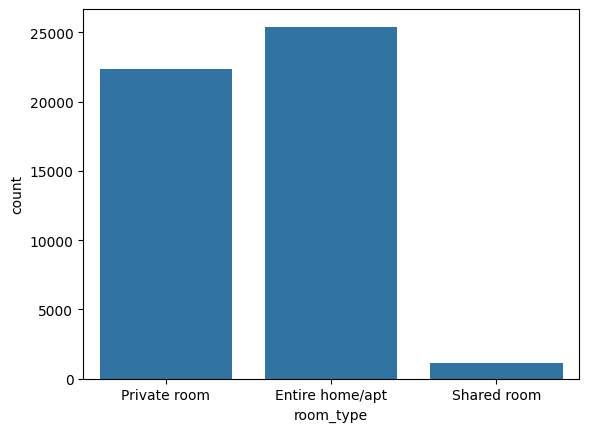

In [131]:
sns.countplot(x='room_type', data=df)

In [132]:
# Calculate missing-value percentage for each feature
missing_percentage = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

missing_percentage

,0
last_review,20.558339
reviews_per_month,20.558339
host_name,0.042949
name,0.032723
neighbourhood_group,0.000000
neighbourhood,0.000000
id,0.000000
host_id,0.000000
longitude,0.000000
latitude,0.000000


In [133]:
df.select_dtypes(include='number').columns

Index(['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights',
       'number_of_reviews', 'reviews_per_month',
       'calculated_host_listings_count', 'availability_365'],
      dtype='object')

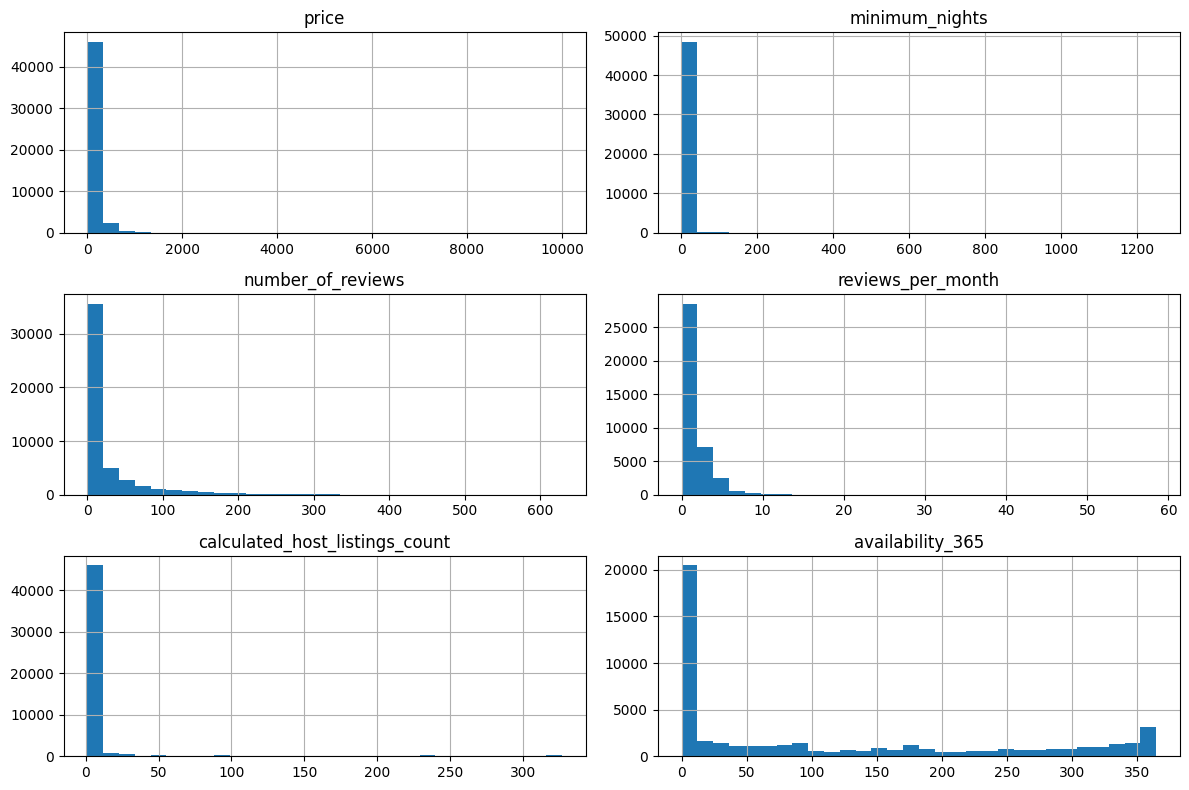

In [134]:
# Define numerical features for distribution analysis
numerical_cols = ['price', 'minimum_nights',
       'number_of_reviews', 'reviews_per_month',
       'calculated_host_listings_count', 'availability_365']

# Visualize feature distributions to identify skewness and potential outliers
df[numerical_cols].hist(bins=30, figsize=(12, 8))

plt.tight_layout()
plt.show()

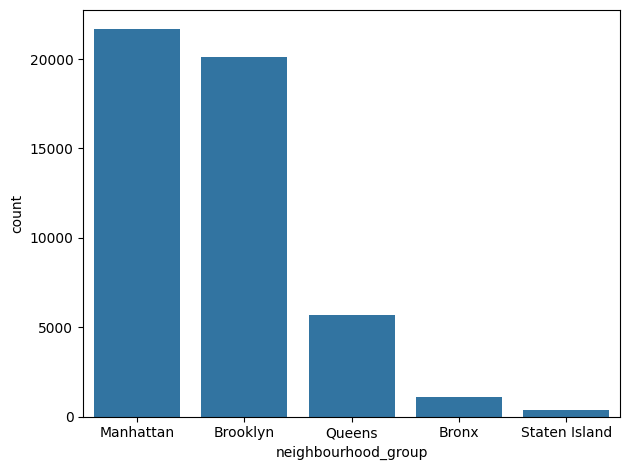

In [135]:
# Compare room-type distributions across NYC boroughs

sns.countplot(data=df, x='neighbourhood_group', order=df["neighbourhood_group"].value_counts().index)

plt.tight_layout()  # reduces label overlap.
plt.show()

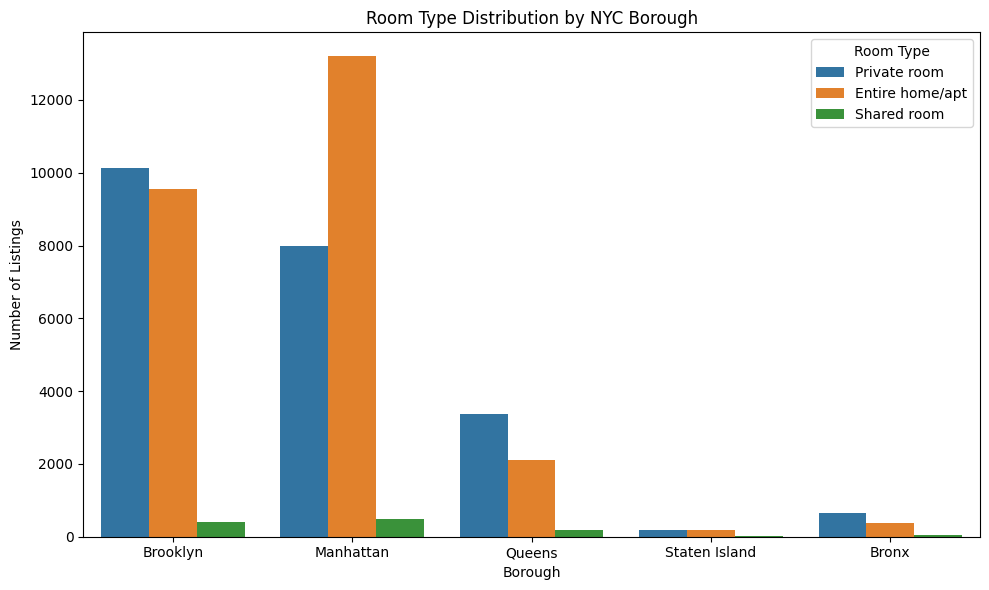

In [136]:
# Compare room-type distributions across NYC boroughs
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="neighbourhood_group",
    hue="room_type"
)

plt.title("Room Type Distribution by NYC Borough")
plt.xlabel("Borough")
plt.ylabel("Number of Listings")
plt.legend(title="Room Type")
plt.tight_layout()
plt.show()

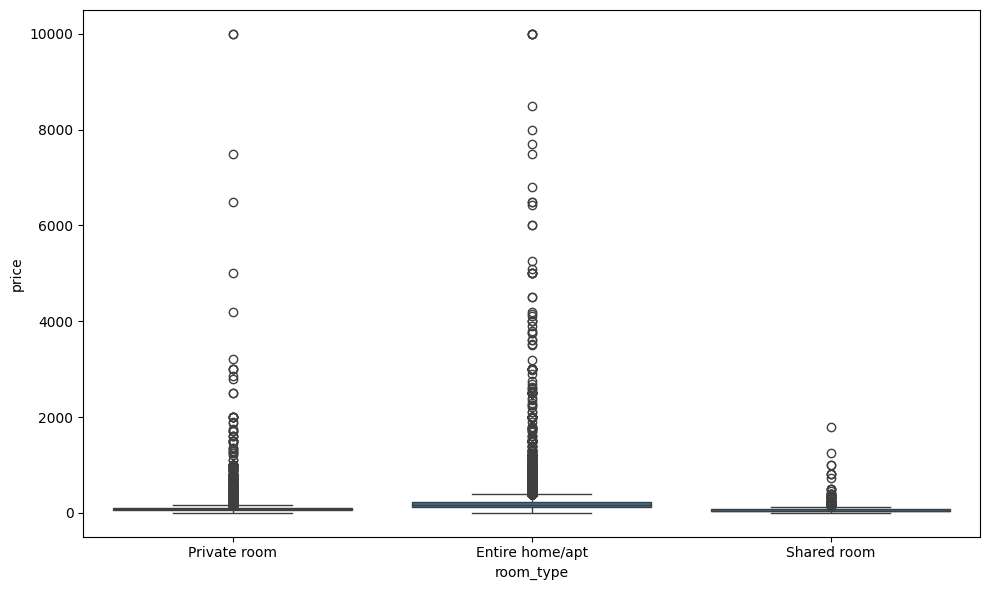

In [137]:
# Compare price distributions across room types
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='room_type', y='price')
plt.tight_layout()
plt.show()

<Axes: >

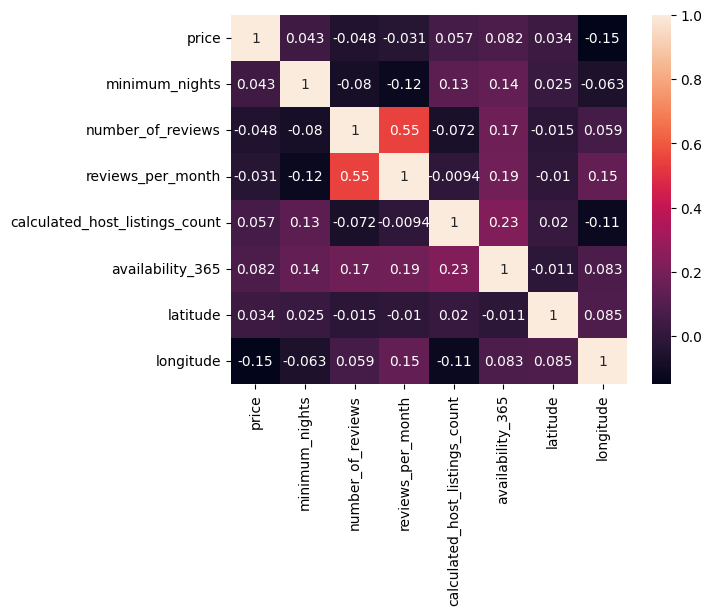

In [138]:
# calculating a correlation matrix and visualizing it with a heatmap
corr = df[numerical_cols + ['latitude', 'longitude']].corr()
sns.heatmap(corr, annot=True)

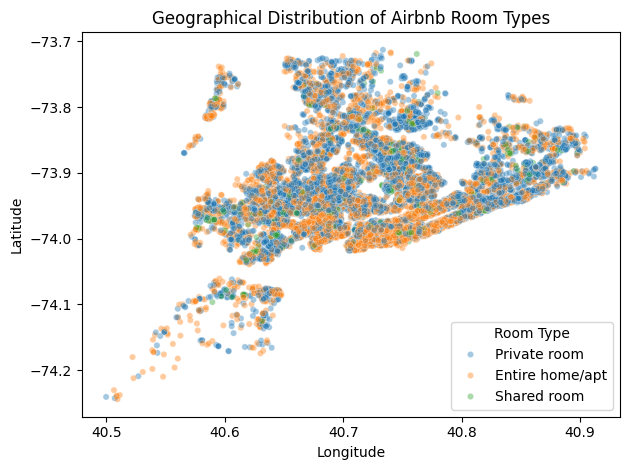

In [139]:
# You're using a geographical scatter plot to visualize Airbnb listings across New York City and distinguish them by room_type.
sns.scatterplot(x='latitude', y='longitude', data=df, hue='room_type', alpha=0.4, s=20)

plt.title("Geographical Distribution of Airbnb Room Types")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Room Type")
plt.tight_layout()
plt.show()

In [140]:
# drop columns that dont help us
df_clean = df.drop(columns = ['id', 'name', 'host_id', 'host_name', 'last_review'])

# Treat missing review frequency as zero for listings with no reviews
df_clean['reviews_per_month'] = df_clean['reviews_per_month'].fillna(0)
df_clean.sample(10)

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
39115,Manhattan,NoHo,40.72696,-73.99501,Entire home/apt,390,15,1,0.91,1,15
31939,Brooklyn,Bedford-Stuyvesant,40.68432,-73.95150,Entire home/apt,110,2,3,0.23,1,0
18566,Brooklyn,Carroll Gardens,40.67954,-73.99935,Private room,100,2,93,2.78,2,74
34244,Brooklyn,Fort Greene,40.68876,-73.97048,Entire home/apt,1200,3,1,0.09,1,0
16621,Brooklyn,Prospect-Lefferts Gardens,40.66071,-73.95580,Entire home/apt,94,3,98,2.71,1,94
20510,Brooklyn,Bushwick,40.70279,-73.92890,Private room,31,7,2,0.06,1,89
36188,Brooklyn,Bushwick,40.69943,-73.93292,Entire home/apt,150,3,3,0.39,1,0
11402,Brooklyn,Cobble Hill,40.68954,-73.99383,Entire home/apt,200,5,7,0.16,1,0
9169,Manhattan,Morningside Heights,40.80481,-73.96375,Private room,45,21,4,0.09,1,0
1988,Brooklyn,Bushwick,40.68777,-73.91601,Private room,62,2,22,0.37,1,87


In [141]:
# Calculate the 99th percentile threshold for each feature
price_cap =  df_clean['price'].quantile(0.99)
nights_cap = df_clean['minimum_nights'].quantile(0.99)

# Cap extreme values at their respective thresholds
df_clean['price']          = df_clean['price'].clip(upper=price_cap)
df_clean['minimum_nights'] = df_clean['minimum_nights'].clip(upper=nights_cap)

# df_clean = df_clean[df_clean['price'] < price_cap]
# df_clean = df_clean[df_clean['minimum_nights'] < nights_cap]

In [142]:
# Separate input features from the target variable
X = df_clean.drop(columns=["room_type"])

# Store the target variable to be predicted
y = df_clean["room_type"]

In [143]:
# Split the dataset into training and testing subsets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42, stratify=y)

# stratify=y Preserves approximately the same proportion of each room type in both subsets.

In [144]:
# Preprocessing - Columntransformer + Pipeline

# fills missing values
from sklearn.impute import SimpleImputer

# executes preprocessing steps in sequence
from sklearn.pipeline import Pipeline

# standardizes numerical features, converts categories into numerical indicator columns
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# applies different pipelines to different columns
from sklearn.compose import ColumnTransformer

In [145]:
# Define numerical features used by the model
numerical_cols = ["latitude","longitude","price", "minimum_nights", "number_of_reviews",
                 "reviews_per_month", "calculated_host_listings_count",
                 "availability_365"]

# Define categorical features used by the model
categorical_cols = ['neighbourhood_group', 'neighbourhood']

# Pipeline for Handle missing numerical values and standardize feature scales
numeric_pipeline = Pipeline(steps=[
    ('impute', SimpleImputer(strategy="median")),
    ('scale', StandardScaler())
])

# Pipeline for Fill missing categories and convert categories into numerical features
categorical_pipeline = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore'))
])

# Apply the appropriate preprocessing pipeline to each feature group
preprocessor = ColumnTransformer(transformers=[
    ("numerical", numeric_pipeline, numerical_cols),
    ("categorical", categorical_pipeline, categorical_cols )
])

preprocessor

ColumnTransformer(transformers=[('numerical',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['latitude', 'longitude', 'price',
                                  'minimum_nights', 'number_of_reviews',
                                  'reviews_per_month',
                                  'calculated_host_listings_count',
                                  'availability_365']),
                                ('categorical',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encode',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['neighbourhood_group', 'neighbourhood'])])

In [146]:
## Verify that all expected columns exist
# Validate that the selected features are available in the dataset
selected_cols = numerical_cols + categorical_cols

missing_cols = set(selected_cols) - set(X_train.columns)

if missing_cols:
    raise ValueError(f"Missing expected feature columns: {missing_cols}")

In [147]:
import warnings
warnings.filterwarnings('ignore')

In [148]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_val_score

In [117]:
# Define the classification models to compare
models = {
    "Logistic Regression" : LogisticRegression(class_weight="balanced",random_state=42),
    "Decision Tree"       : DecisionTreeClassifier(class_weight="balanced",random_state=42),
    "Random Forest"       : RandomForestClassifier(class_weight="balanced", random_state=42),
    "Gradient Boosting"   : GradientBoostingClassifier(random_state=42),
}

# Evaluate each model using multiple metrics in one cross-validation run
for name, model in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", model)])

    # Accuracy alone can be misleading on imbalanced classes, so we use macro f1
    # both: plain accuracy and macro f1 (which treats every class equally)

    accuracy = cross_val_score(pipe, X_train, y_train,cv=3,scoring="accuracy")
    macrof1 = cross_val_score(pipe, X_train, y_train,cv=3,scoring="f1_macro")

    print(f"{name} -> Accuracy: {accuracy.mean():.3f} , F1: {macrof1.mean():.3f}")

Logistic Regression -> Accuracy: 0.659 , F1: 0.522
Decision Tree -> Accuracy: 0.782 , F1: 0.647
Random Forest -> Accuracy: 0.851 , F1: 0.715
Gradient Boosting -> Accuracy: 0.850 , F1: 0.705


In [118]:
from sklearn.model_selection import RandomizedSearchCV

# Combine preprocessing and the baseline classifier
best_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier",   RandomForestClassifier(class_weight='balanced'))
])

# Define the hyperparameter search space
param_distribution = {
    "classifier__n_estimators" : [100,200,150,300],
    "classifier__max_depth": [8, 12, 15, 20, None],
    "classifier__min_samples_split": [2, 5, 10],
}

# Search for the configuration with the best macro F1-score
search = RandomizedSearchCV(
    estimator=best_pipeline,
    param_distributions=param_distribution,
    n_iter=10,
    cv=3,
    scoring="f1_macro",
    random_state=42
    )

# Tune the model using training data only
search.fit(X_train, y_train)


RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('numerical',
                                                                               Pipeline(steps=[('impute',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('scale',
                                                                                                StandardScaler())]),
                                                                               ['latitude',
                                                                                'longitude',
                                                                                'price',
                                                                                'minimum_nights',
                                                                                'number_of_reviews',
                                                                                'reviews_per_month',
                                                                                'calculated_host_listings_count',
                                                                                'availability_365']),
                                                                              ('categ...
                                                                                                SimpleImputer(strategy='most_frequent')),
                                                                                               ('encode',
                                                                                                OneHotEncoder(handle_unknown='ignore'))]),
                                                                               ['neighbourhood_group',
                                                                                'neighbourhood'])])),
                                             ('classifier',
                                              RandomForestClassifier(class_weight='balanced'))]),
                   param_distributions={'classifier__max_depth': [8, 12, 15, 20,
                                                                  None],
                                        'classifier__min_samples_split': [2, 5,
                                                                          10],
                                        'classifier__n_estimators': [100, 200,
                                                                     150,
                                                                     300]},
                   random_state=42, scoring='f1_macro')

In [119]:
# Display the best configuration and cross-validation score
print("Best parameters:", search.best_params_)
print('Best CV macro F1:', search.best_score_)

Best parameters: {'classifier__n_estimators': 200, 'classifier__min_samples_split': 10, 'classifier__max_depth': None}
Best CV macro F1: 0.7349775819210072


In [120]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

# Retrieve the best pipeline selected by hyperparameter tuning
best_pipeline = search.best_estimator_

# Generate predictions for the unseen test dataset
y_pred = best_pipeline.predict(X_test)

# Evaluate overall classification performance
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
print(f"Macro F1 Score: {f1_score(y_test, y_pred, average='macro'):.4f}")

# Inspect prediction errors across room types
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy Score: 0.8550
Macro F1 Score: 0.7405
Confusion Matrix:
[[7342 1042    1]
 [1028 6320   20]
 [  34  214  135]]


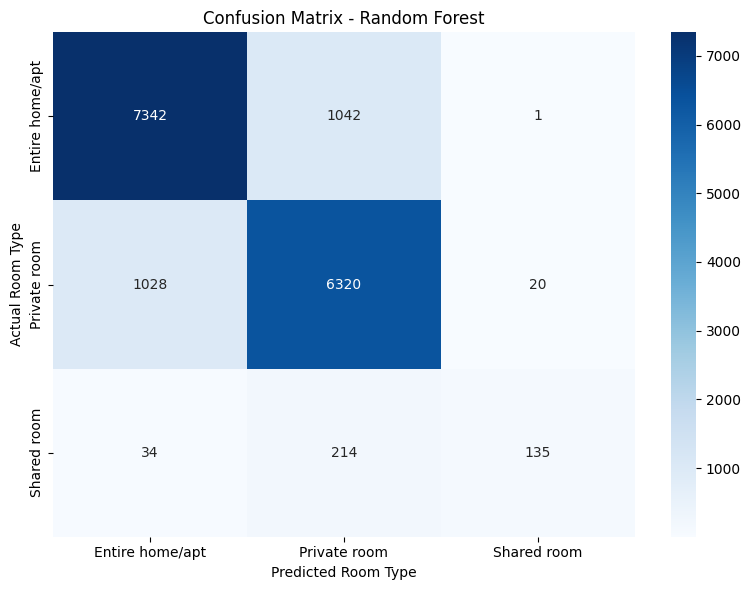

In [121]:
# Calculate the confusion matrix using actual and predicted labels
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=best_pipeline.classes_
)

# Visualize classification performance across room types
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=best_pipeline.classes_,
    yticklabels=best_pipeline.classes_
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Room Type")
plt.ylabel("Actual Room Type")
plt.tight_layout()
plt.show()

In [122]:
import joblib
# Save the trained pipeline, including preprocessing and the classifier
joblib.dump(best_pipeline, 'Model_Pipeline.pkl', compress=3)

['Model_Pipeline.pkl']